In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='white')
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.titlepad': 14,
    'axes.labelpad': 8,
})

# Faculty abbreviations (used in all plots for readability)
FACULTY_ABBREV = {
    'Faculty of Social Science & Public Policy':                'SSPP',
    'Faculty of Natural, Mathematical & Engineering Sciences':  'NMES',
    'Faculty of Dentistry, Oral & Craniofacial Sciences':       'DOCS',
    'Faculty of Life Sciences & Medicine':                      'LSM',
    'Institute of Psychiatry, Psychology & Neuroscience':       'IoPPN',
    'Faculty of Arts & Humanities':                             'AH',
    'Research Management & Innovation':                         'RMI',
    "King's Business School":                                   'KBS',
    'Students & Education':                                     'SE',
    'The Dickson Poon School of Law':                           'DPSL',
    'IT':                                                       'IT',
    'Other':                                                    'Other',
    'unknown':                                                  'N/A',
}

FACULTY_MERGE = {
    'Faculty of Life Sciences and Medicine':
        'Faculty of Life Sciences & Medicine',
    'IoPPN':
        'Institute of Psychiatry, Psychology & Neuroscience',
    'Dentistry, Oral & Craniofacial Sciences':
        'Faculty of Dentistry, Oral & Craniofacial Sciences',
    'Social Science & Public Policy':
        'Faculty of Social Science & Public Policy',
}

unix_zerotime = pd.to_datetime("1970-01-01 00:00", utc=True)

In [2]:
## function definitions
def read_job_metrics(input_file):
    df = pd.read_csv(input_file, comment='#')
    df['faculty'] = df['faculty'].str.strip('"')
    df = df.replace('NULL', np.nan)

    num_cols = [c for c in df.columns
                if c not in ('username', 'faculty', 'submission_type', 'mem_type', 'partition')]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    dt_cols = ['time_start', 'time_end']
    for c in dt_cols:
        df[c] = pd.to_datetime(df[c], unit = "s", utc=True)
    return df

def fix_faculty_labels(df, faculty_merge, faculty_abbrev):
    df['faculty'] = df['faculty'].replace(faculty_merge)
    # Use abbreviations for plot labels
    df['faculty_short'] = df['faculty'].map(faculty_abbrev).fillna(df['faculty'])
    return df

## Read data since May 2022

In [3]:
input_files = [
    "../results/data/2022-05-01_2024-08-31_job_level_metrics_all_jobs.csv", 
    "../results/data/2024-08-26_2026-08-26_job_level_metrics_all_jobs.csv", 
    "../results/data/2026-08-25_2026-09-07_job_level_metrics_all_jobs.csv", 
    "../results/data/2026-09-07_2026-10-15_job_level_metrics_all_jobs.csv"
    ]

df_list = [read_job_metrics(input) for input in input_files]
df = pd.concat(df_list).drop_duplicates()
df = fix_faculty_labels(df, faculty_merge=FACULTY_MERGE, faculty_abbrev=FACULTY_ABBREV)

print(f'Included jobs: {len(df):,}')

Included jobs: 37,964,778


In [4]:
# calculate additional required columns
df['time_submit'] = df['time_start'] - pd.to_timedelta(df['wait_sec'], unit='s')
df['submit_day'] = df['time_submit'].dt.floor('D')
df['submit_month'] = df['submit_day'].dt.strftime('%Y-%m')

df['start_day'] = df['time_start'].dt.floor('D')
df['month'] = df['submit_day'].dt.strftime('%m')

# filter out first month in data
df = df[df['submit_month'] != '2022-04']
# filter invalid submit times - jobs that never started
df = df[df['submit_day'] != unix_zerotime]

print(f'Included jobs after filtering: {len(df):,}')

Included jobs after filtering: 36,690,247


In [5]:
legend_order = df['month'].drop_duplicates().sort_values()
legend_order

1166707    01
1472175    02
1665498    03
1956593    04
66         05
28354      06
80599      07
209711     08
436858     09
720971     10
918362     11
1084491    12
Name: month, dtype: str

## Usage analysis over time

In [6]:
df_to_plot = (
    df[['submit_day', 'submit_month', 'month', 'username']]
    .drop_duplicates()
    .groupby(["submit_day", "submit_month", 'month'])
    .count()
    .reset_index()
)

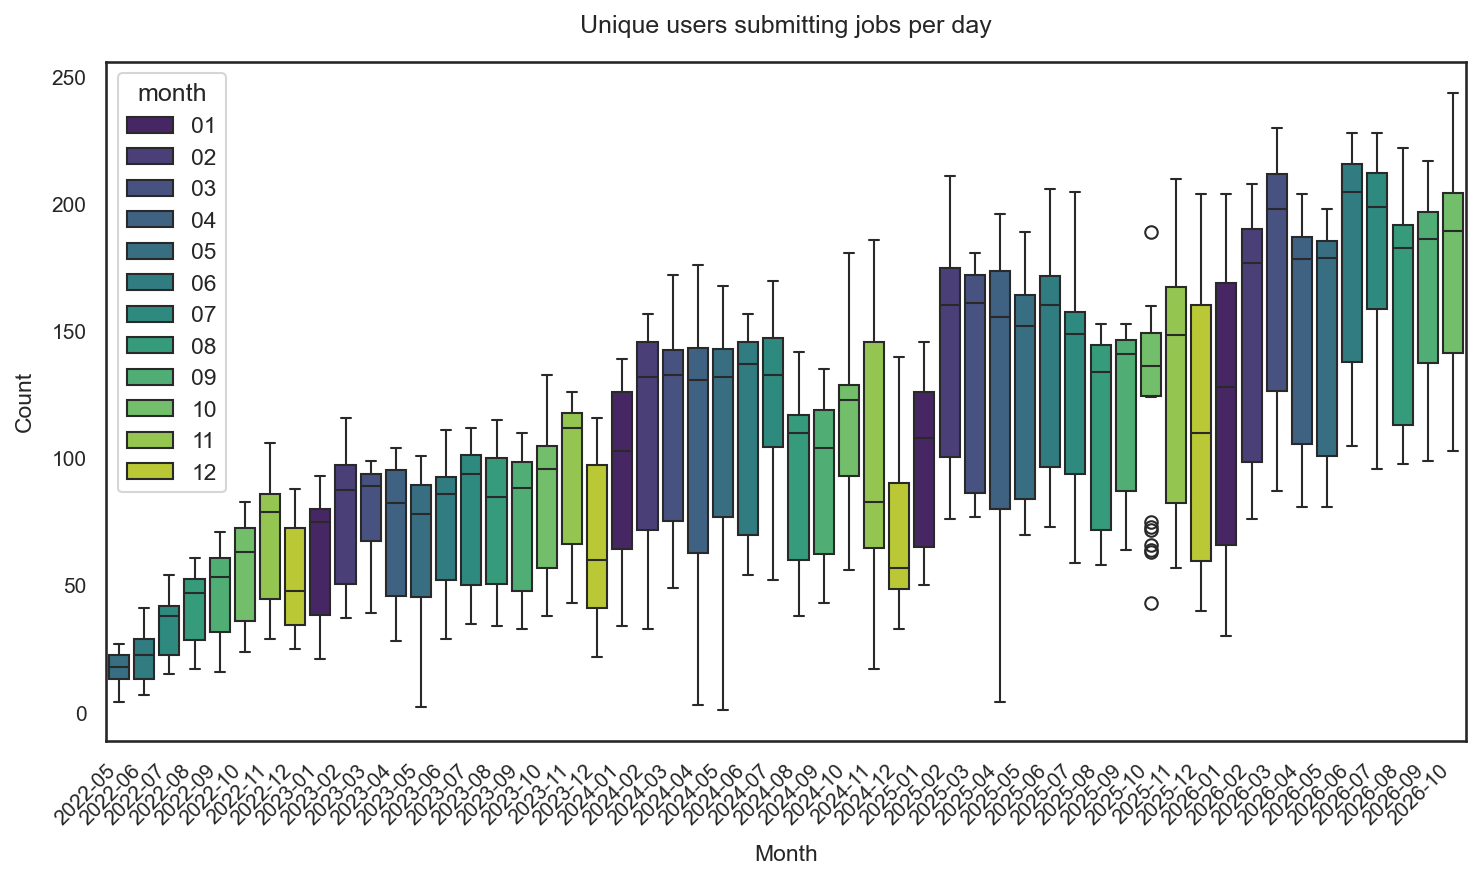

In [7]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_to_plot, x='submit_month', y='username', hue='month', 
            hue_order=legend_order, palette='viridis')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Month')
plt.ylabel('Count')
plt.title('Unique users submitting jobs per day')
plt.tight_layout()
plt.show()

In [8]:
df_to_plot = (
    df[['submit_month', 'month', 'username']]
    .drop_duplicates()
    .groupby(["submit_month", "month"])
    .count()
    .reset_index()
    )

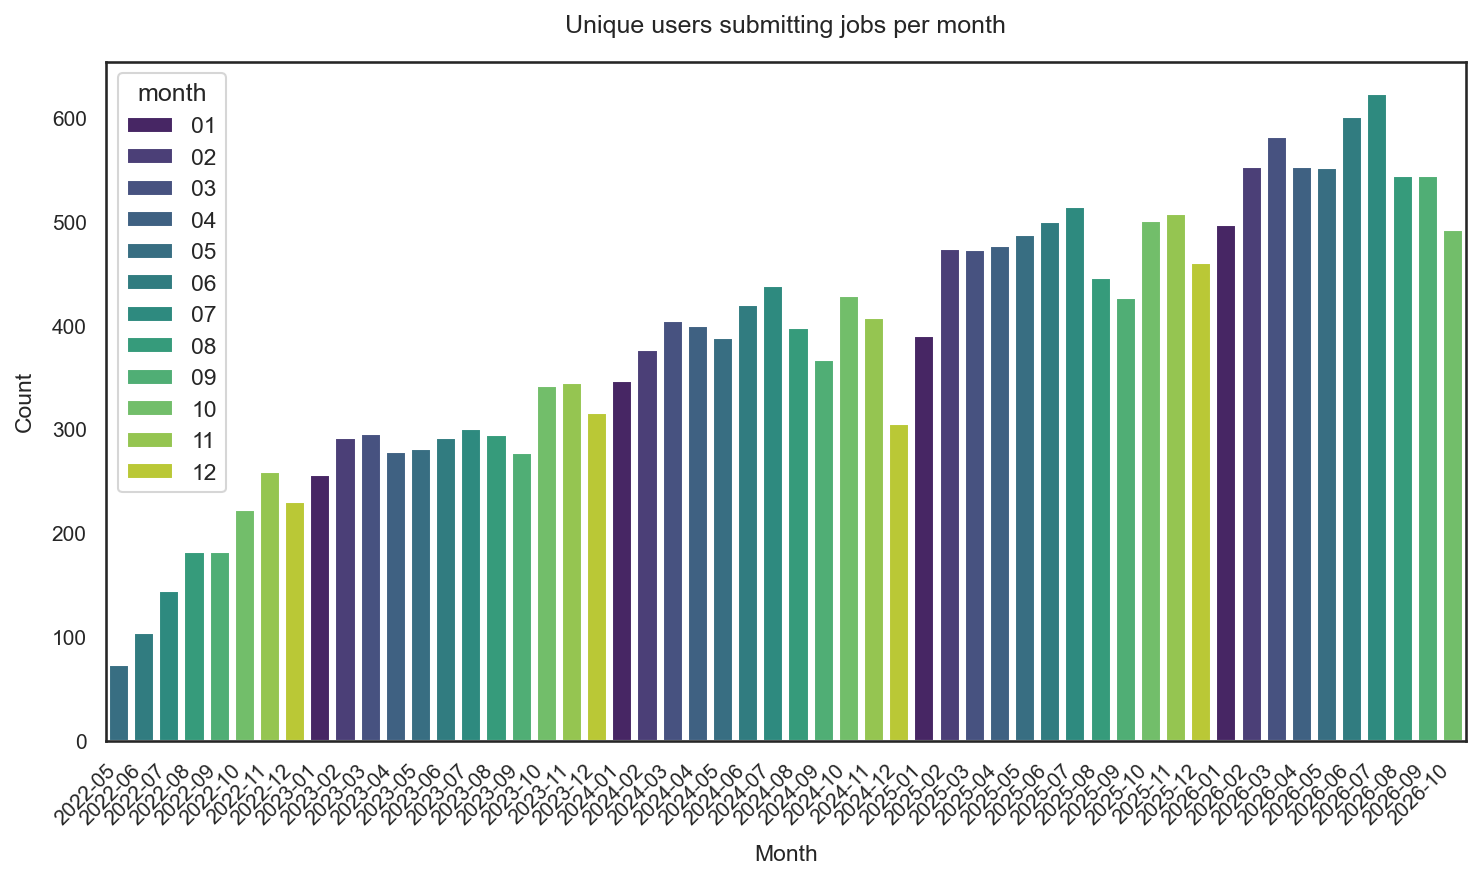

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(data=df_to_plot, x='submit_month', y='username', hue='month', 
            hue_order=legend_order, palette='viridis')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Month')
plt.ylabel('Count')
plt.title('Unique users submitting jobs per month')
plt.tight_layout()
plt.show()

In [10]:
df_to_plot = (
    df[['submit_day', 'submit_month', 'month', 'job_id']]
    .groupby(["submit_day", 'submit_month', 'month',])
    .count()
    .reset_index()
    )

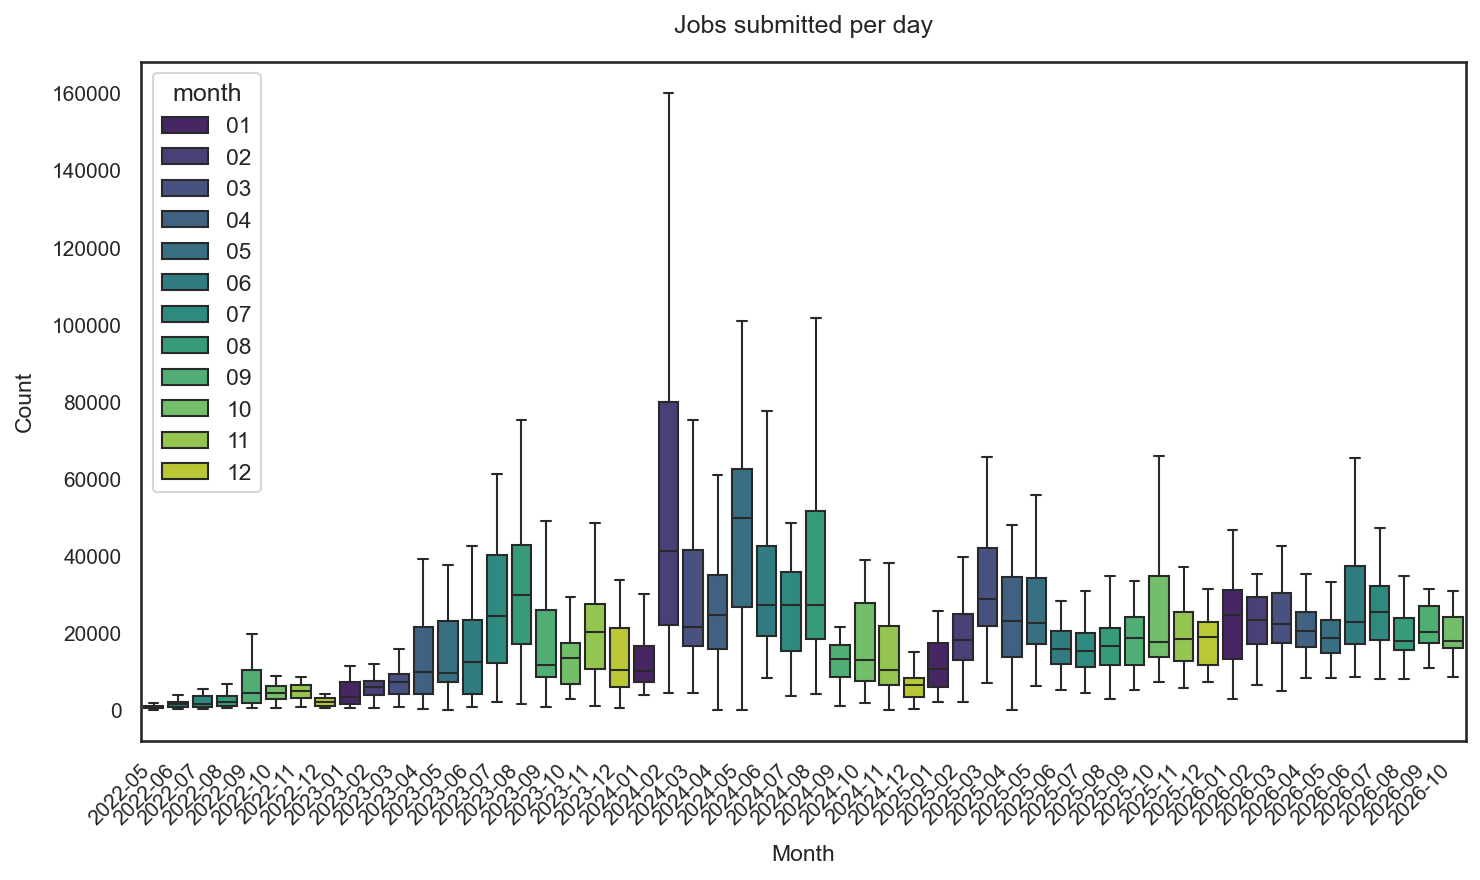

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_to_plot, x='submit_month', y='job_id', hue='month', 
            hue_order=legend_order, palette='viridis', showfliers=False)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Month')
plt.ylabel('Count')
plt.title('Jobs submitted per day')
plt.tight_layout()
plt.show()

In [12]:
df_to_plot = (
    df[['submit_day','submit_month', 'month', 'req_cpus']]
    .groupby(["submit_day", 'submit_month', 'month',])
    .sum()
    .reset_index()
)

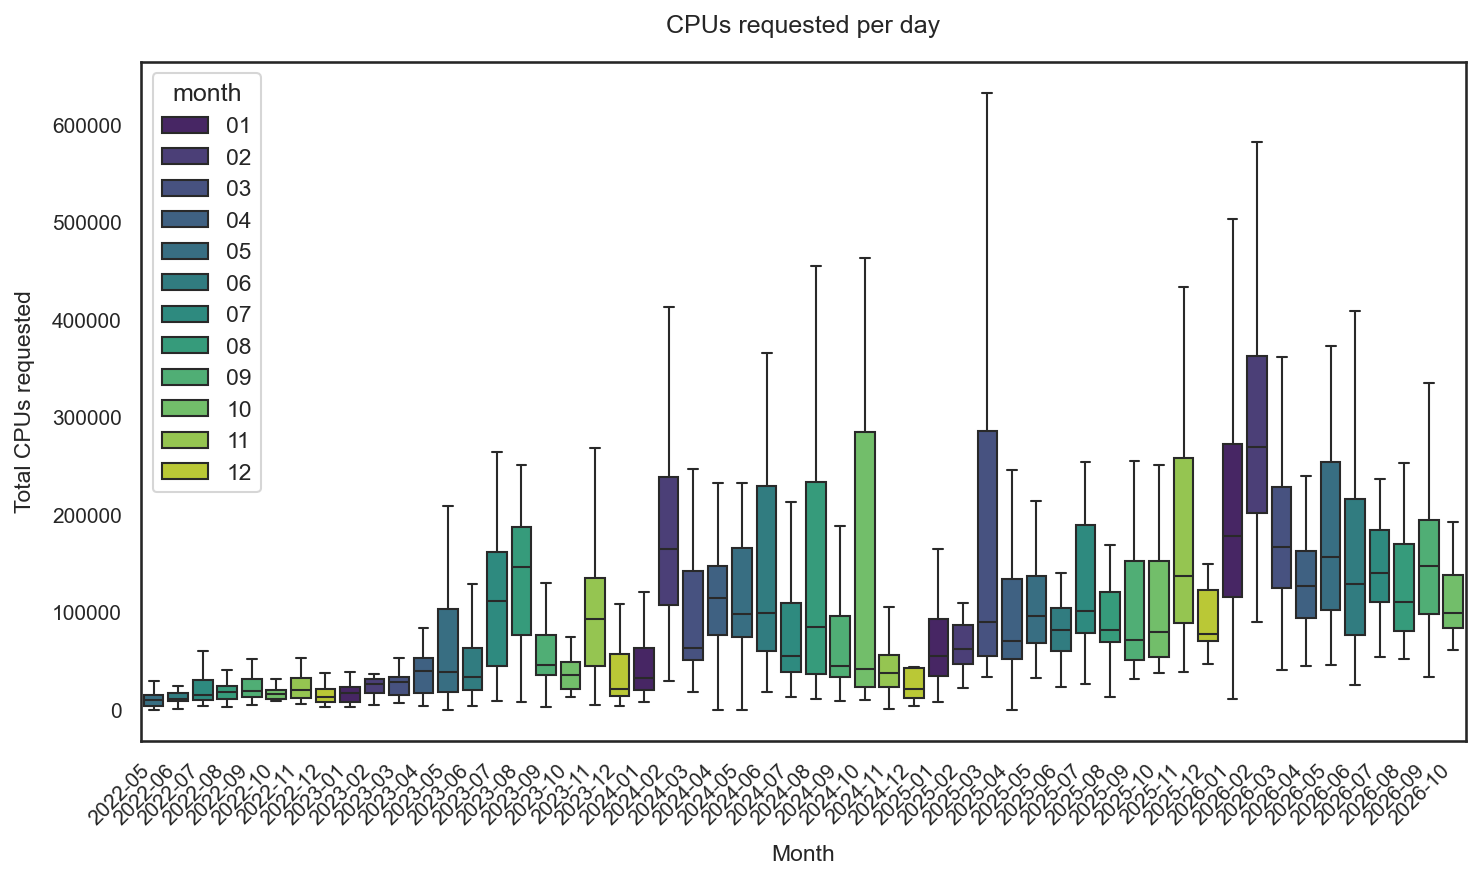

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_to_plot, x='submit_month', y='req_cpus', hue='month', 
            hue_order=legend_order, palette='viridis', showfliers=False)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Month')
plt.ylabel('Total CPUs requested')
plt.title('CPUs requested per day')
plt.tight_layout()
plt.show()